
<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_04_reg_lin_grad_desc_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>




# **Laboratorio N°4: Regresión Lineal  - Gradiente Descendiente**

**Curso:** Aprendizaje Estadistico 2026-2  
**Estudiante:** Jeronimo Lopez Gomez

------

Los modelos de aprendizaje estadístico que pueden ser industrializados pueden ser [esquematizados](https://proceedings.neurips.cc/paper/2015/file/86df7dcfd896fcaf2674f757a2463eba-Paper.pdf), según se muestra en la siguiente imagen:

![MLOPs](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/Sesion_04_MLOP_General.png?raw=true)

![MLOPs](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/Sesion_04_MLOPS.png?raw=true)

A partir de ahora, nos concentraremos en entender los modelos que ocurren dentro de la caja negra y cómo encajan dentro de una estructura general de los modelos de machine learning.

De forma general, un modelo de [ML](https://www.coursera.org/learn/machine-learning) puede ser visualizado de la siguiente manera:

![SupervisedModel](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/Sesion_04_GeneralTraining.png?raw=true)

## ¿Cuál es el mejor enfoque para optimizar un problema?

[No Free Lunch Theorems for Optimization](https://ieeexplore.ieee.org/document/585893):

Para cada par de algoritmos, existen tantos problemas en los que el primer algoritmo es mejor que el segundo como problemas en los que el segundo es mejor que el primero. Como consecuencia, no existe un único algoritmo universalmente mejor para optimizar todos los problemas; por ello, siempre es recomendable emplear cierto conocimiento específico del problema que se desea resolver.

## Estructura general de los problemas de ML

1. Construir la hipótesis.
2. Elegir los parámetros.
3. Elegir la función de coste.
4. Minimizar la función de coste.
5. Validar y entrenar el modelo.

## Aprendizaje supervisado

- Datos etiquetados.
- Retroalimentación directa.
- Predicción de resultados.

## Regresión lineal

Supongamos que tenemos un sistema en el que existe un predictor con **m** valores de entrenamiento, así:

$$(x^{(1)}, y^{(1)}), (x^{(2)}, y^{(2)}), \dots, (x^{(m)}, y^{(m)})$$

| Muestra | $Y$       | $X_1$       |
|--------:|:---------:|:-----------:|
| 1       | $Y^{(1)}$ | $X_1^{(1)}$ |
| 2       | $Y^{(2)}$ | $X_1^{(2)}$ |
| $\vdots$| $\vdots$  | $\vdots$    |
| $m$     | $Y^{(m)}$ | $X_1^{(m)}$ |

Podemos definir un modelo lineal como

$$
h(X)=\theta_0+\theta_1X
$$

donde $(\theta_0,\theta_1)$ son los parámetros del modelo. Nuestro objetivo es encontrar el conjunto de parámetros $(\theta_0,\theta_1)$ que se encuentre más "cercano" a $Y$ para cada valor de $X$.

Para la optimización, vamos a definir la función de coste **$J(\theta_0,\theta_1)$** para las muestras de entrenamiento como aquella que mide la distancia euclidiana respecto a la hipótesis planteada, así:

\begin{equation}
J(\theta_0,\theta_1)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_{\theta}(x^{(i)})-y^{(i)}\right)^2
\end{equation}

Para encontrar los valores de $(\theta_0,\theta_1)$ se necesita minimizar la función de coste, lo que permite obtener los valores más cercanos. Esta minimización puede realizarse a través de diferentes métodos; el más conocido es el gradiente descendente.


![](https://github.com/hernansalinas/Curso_aprendizaje_estadistico/blob/main/Sesiones/imagenes/fig00.png?raw=true=50x)



Supongamos un modelo lineal para realizar la predicción. Así, nuestro modelo estará basado en la siguiente hipótesis de trabajo:

$$
h(X)=\theta_0+\theta_1X
$$

donde $\theta_0$ y $\theta_1$ corresponden a los parámetros del modelo.

Reemplazando el modelo anterior en la función de coste, obtenemos:

\begin{equation}
J(\theta_0,\theta_1)=\frac{1}{2m}\sum_{i=1}^{m}\left((\theta_0+\theta_1x^{(i)})-y^{(i)}\right)^2
\end{equation}

-------------

----

## **Desarrollo Laboratorio**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    # Tipografía
    'font.family': 'serif',
    'font.serif': ['STIX Two Text', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'axes.titleweight': 'semibold',
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,

    # Figura
    'figure.figsize': (8,6),
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.08,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    # Ejes
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.9,
    'axes.labelcolor': '#222222',
    'axes.titlecolor': '#222222',
    'axes.spines.top': False,
    'axes.spines.right': False,

    # Cuadrícula
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#D9DDE3',
    'grid.linestyle': '--',
    'grid.linewidth': 0.6,
    'grid.alpha': 0.65,

    # Ticks
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,

    # Líneas
    'lines.linewidth': 2,
    'lines.markersize': 5,

    # Leyenda
    'legend.frameon': False,
    'legend.loc': 'best',

    # Exportación
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

# Paleta de colores
COLORS = [
    '#0072B2',  # Azul
    '#D55E00',  # Naranja rojizo
    '#009E73',  # Verde
    '#CC79A7',  # Violeta
    '#E69F00',  # Naranja
    '#56B4E9',  # Celeste
    '#333333',  # Gris oscuro
]

**1.)** Construya un `DataFrame` de pandas con un conjunto de datos lineales simples.

Definamos un conjunto de datos simulado correspondiente a un sistema sometido a una fuerza restauradora $F = -kx$ donde denotamos como $\sigma$ al ruido experimental asociado a las mediciones de la fuerza restauradora.

findfont: Failed to find font weight semibold, now using 700.


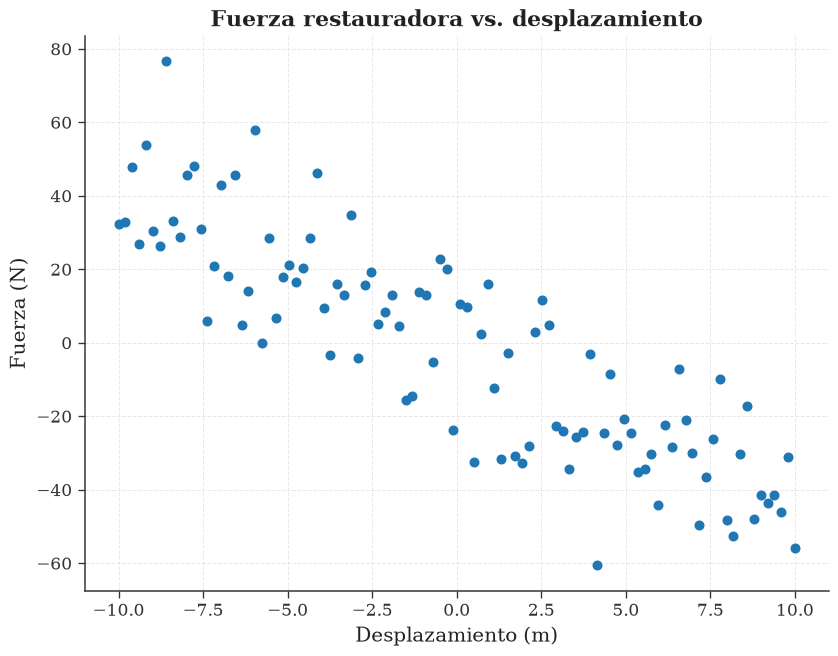

In [2]:
#1. Definimos un df con datos simulados de una fuerza restauradora F = -kx 
 
num_dat = 100 
 
k = 4.5             # Constante efectiva [N/m] 
dev = 15.0          # Ruido experimental [N] 
 
df = pd.DataFrame({ 
    'Desplazamiento': np.linspace(-10, 10, num_dat), 
    'Fuerza': (-k * np.linspace(-10, 10, num_dat) + np.random.normal(0, dev, num_dat)) 
}) 

plt.figure()
plt.scatter(df['Desplazamiento'], df['Fuerza'], marker='o', zorder=2) 
 
plt.xlabel('Desplazamiento (m)') 
plt.ylabel('Fuerza (N)') 
plt.title('Fuerza restauradora vs. desplazamiento') 
 
plt.grid(True, zorder=0) 

plt.show()

----

**2.)** Defina una función que calcule la función de coste cuadrática para un modelo de regresión lineal.

$$
h(X) = \theta_0 + \theta_1 X
$$

**3.)** Fijando inicialmente $\theta_0=0$, evalúe y grafique la función de coste para diferentes valores de $\theta_1$. Determine el valor que minimiza la función de coste y grafique la recta obtenida sobre los datos.

In [3]:
#2. Definamos ahora una función de coste cuadratica para regresion lineal
def linear_model(theta, X):
    return theta[0] + theta[1] * X

def coste_func(model, X, Y):
    """
    Calcula el coste cuadrático para una regresión lineal.
    model: función que representa el modelo lineal.
    X: array de características
    Y: array de valores reales
    """
    m = len(Y)
    predict = model(X)
    J = (1/(2*m)) * np.sum((predict - Y)**2)
    return J

------- MINIMO THETA_1 ---------
El valor de theta_1 que minimiza el coste cuadrático es: -4.3434


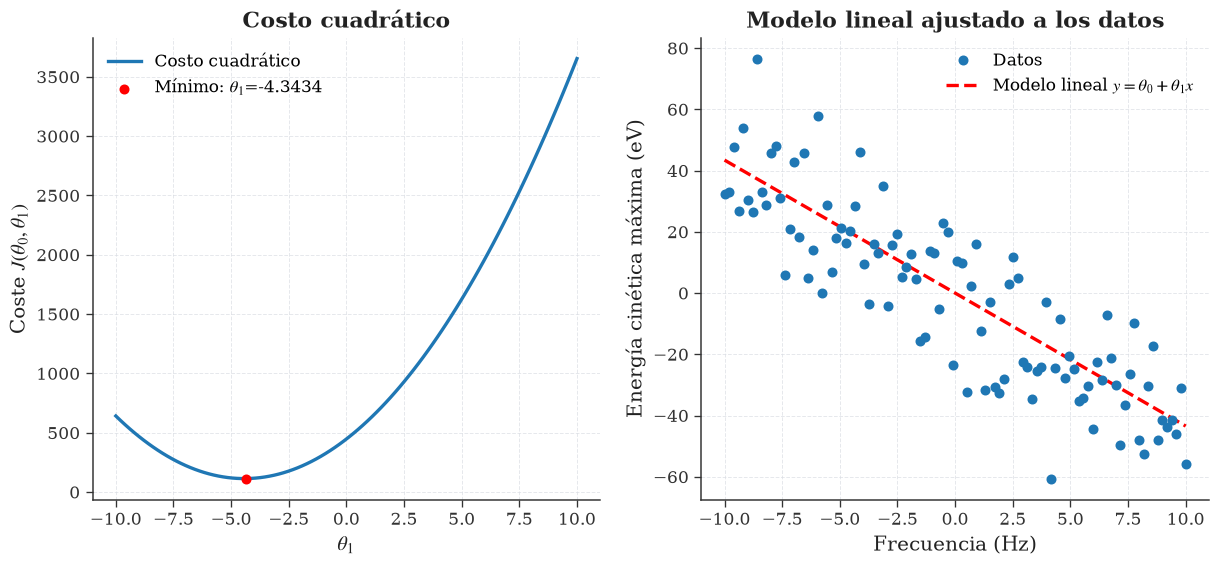

In [4]:
#3. Fijamos theta_0 = 0 y variamos en theta_1 para ver como cambia el coste cuadrático

theta_0 = 0  # Inicializamos theta_0
theta_1_vals = np.linspace(-10, 10, 100)  # Valores de theta_1 a evaluar

X = df['Desplazamiento'].to_numpy()
Y = df['Fuerza'].to_numpy()

coste = []

for theta_i in theta_1_vals:

    model = lambda x: linear_model([theta_0, theta_i], x)

    coste.append(coste_func(model, X, Y))


#Determinemos ahora el theta_1 que minimiza el coste cuadrático
min_coste_idx = np.argmin(coste)
min_theta_1 = theta_1_vals[min_coste_idx]

print('------- MINIMO THETA_1 ---------')
print(f"El valor de theta_1 que minimiza el coste cuadrático es: {min_theta_1.round(4)}")
#Graficamos el coste cuadrático en función de theta_1 y el modelo lineal ajustado a los datos

fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].plot(theta_1_vals, coste, zorder = 2, label='Costo cuadrático')
ax[0].scatter(min_theta_1, coste[min_coste_idx], color='red',
            label=f'Mínimo: $\\theta_1$={min_theta_1.round(4)}', zorder = 3)
ax[0].set_title('Costo cuadrático')
ax[0].set_xlabel('$\\theta_1$')
ax[0].set_ylabel('Coste $J(\\theta_0, \\theta_1)$')
ax[0].grid(True, zorder = 0)
ax[0].legend()

#Graficamos el modelo lineal ajustado a los datos
pred_model = lambda X: linear_model([theta_0, min_theta_1], X)

ax[1].plot(X, Y, 'o', label='Datos', zorder = 4)
ax[1].plot(X, pred_model(X), label='Modelo lineal $y = \\theta_0 + \\theta_1 x$', color='red', linestyle='--', zorder = 2)
ax[1].set_title('Modelo lineal ajustado a los datos')
ax[1].set_xlabel('Frecuencia (Hz)')
ax[1].set_ylabel('Energía cinética máxima (eV)')
ax[1].grid(True, zorder = 0)
ax[1].legend()
plt.show()

----

**4.)** Permita ahora que tanto $\theta_0$ como $\theta_1$ varíen. Construya una malla con `np.meshgrid`, evalúe la función de coste en cada punto y represente su superficie y curvas de nivel.

findfont: Failed to find font weight semibold, now using 700.


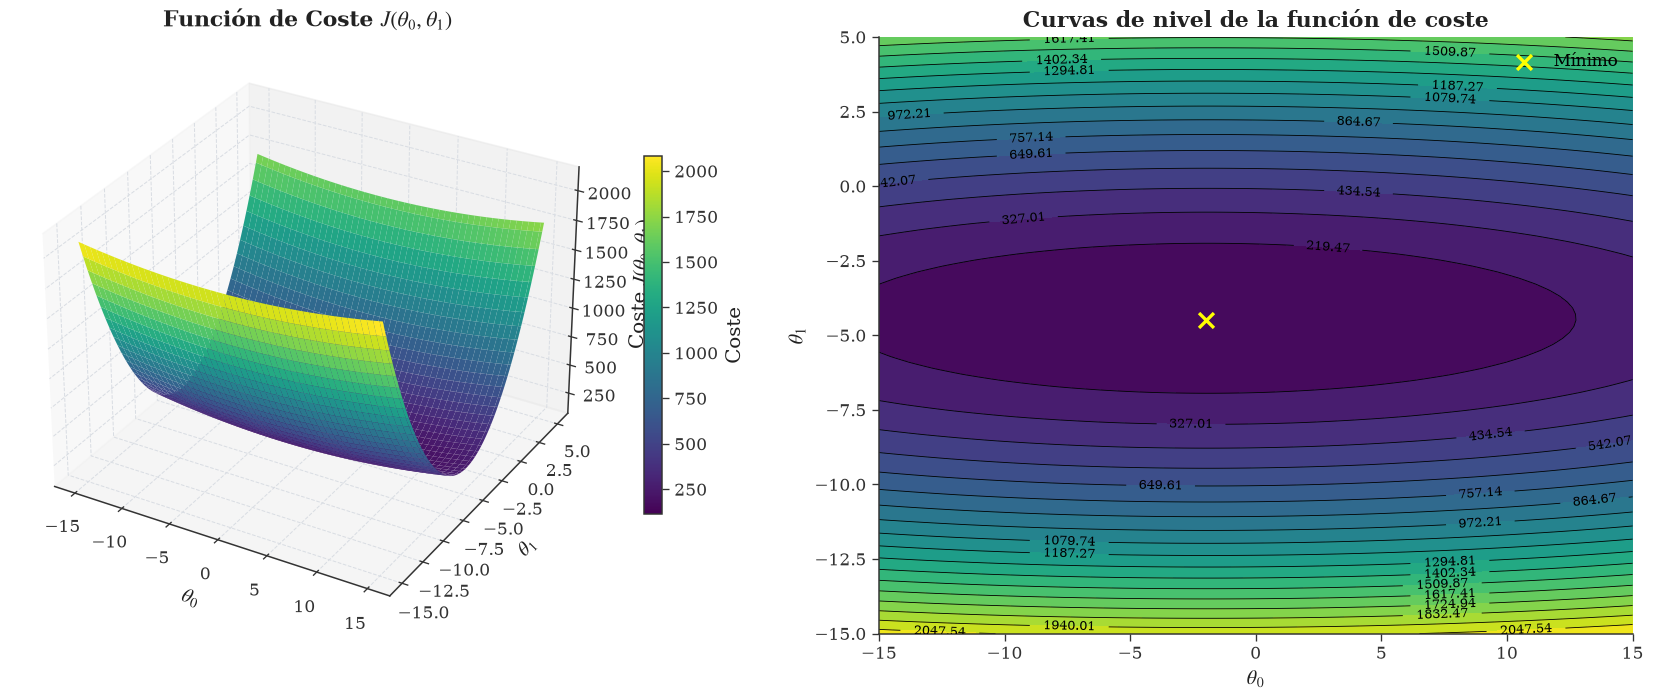

------- MINIMO THETA_0 Y THETA_1 ---------
El valor de theta_0 que minimiza el coste cuadrático es: -1.9697
El valor de theta_1 que minimiza el coste cuadrático es: -4.4949


In [5]:
# 4. Variamos theta_0 y theta_1 para ver cómo cambia el coste cuadrático

# Generamos una malla de valores para theta_0 y theta_1
theta_0_grid, theta_1_grid = np.meshgrid(
    np.linspace(-15, 15, 100),
    np.linspace(-15, 5, 100)
)

def linear_model_grid(theta_0_grid, theta_1_grid, X):
    return theta_0_grid[:, np.newaxis] + theta_1_grid[:, np.newaxis] * X

predictions = linear_model_grid(theta_0_grid, theta_1_grid, X)

# Calculamos el coste cuadrático para cada combinación de theta_0 y theta_1

def coste_func_grid(theta_0_grid, theta_1_grid, X, Y):
    J_grid = np.zeros_like(theta_0_grid)

    for i in range(theta_0_grid.shape[0]):
        for j in range(theta_0_grid.shape[1]):
            t0 = theta_0_grid[i, j]
            t1 = theta_1_grid[i, j]
            
            # Modelo con los thetas actuales
            prediccion = t0 + t1 * X
            
            # Coste cuadrático
            J_grid[i, j] = (1 / (2 * len(Y))) * np.sum((prediccion - Y)**2)

    return J_grid

J_grid_result = coste_func_grid(theta_0_grid, theta_1_grid, X, Y)

#Graficación 
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')

surf = ax1.plot_surface(
    theta_0_grid,
    theta_1_grid,
    J_grid_result,
    cmap='viridis',
    edgecolor='none'
)

ax1.set_title(r'Función de Coste $J(\theta_0,\theta_1)$')
ax1.set_xlabel(r'$\theta_0$')
ax1.set_ylabel(r'$\theta_1$')
ax1.set_zlabel(r'Coste $J(\theta_0,\theta_1)$')

fig.colorbar(
    surf,
    ax=ax1,
    shrink=0.6,
    label='Coste'
)


# Graficación de curvas de Nivel

ax2 = fig.add_subplot(1, 2, 2)

levels = np.linspace(
    np.min(J_grid_result),
    np.max(J_grid_result),
    20
)

contourf = ax2.contourf(
    theta_0_grid,
    theta_1_grid,
    J_grid_result,
    levels=levels,
    cmap='viridis'
)

contours = ax2.contour(
    theta_0_grid,
    theta_1_grid,
    J_grid_result,
    levels=levels,
    colors='black',
    linewidths=0.5
)

# Etiquetas de las líneas de nivel
ax2.clabel(
    contours,
    inline=True,
    fontsize=8,
    fmt='%.2f'
)


#Calculamos el minimo de la funcion de coste y lo graficamos en la curva de nivel

min_idx = np.unravel_index(np.argmin(J_grid_result), J_grid_result.shape)

#Graficamos los puntos de mínimo en la curva de nivel
ax2.scatter(theta_0_grid[min_idx],theta_1_grid[min_idx],color='yellow',marker='x',s=80,label='Mínimo')

ax2.set_title('Curvas de nivel de la función de coste')
ax2.set_xlabel(r'$\theta_0$')
ax2.set_ylabel(r'$\theta_1$')
ax2.grid(True)
ax2.legend()


# Ajustamos el diseño
plt.tight_layout()
plt.show()

print('------- MINIMO THETA_0 Y THETA_1 ---------')
print(f"El valor de theta_0 que minimiza el coste cuadrático es: {theta_0_grid[min_idx].round(4)}")
print(f"El valor de theta_1 que minimiza el coste cuadrático es: {theta_1_grid[min_idx].round(4)}")

Grafiquemos el Ajuste lineal con los valores de theta_0 y theta_1 que minimizan el coste cuadrático


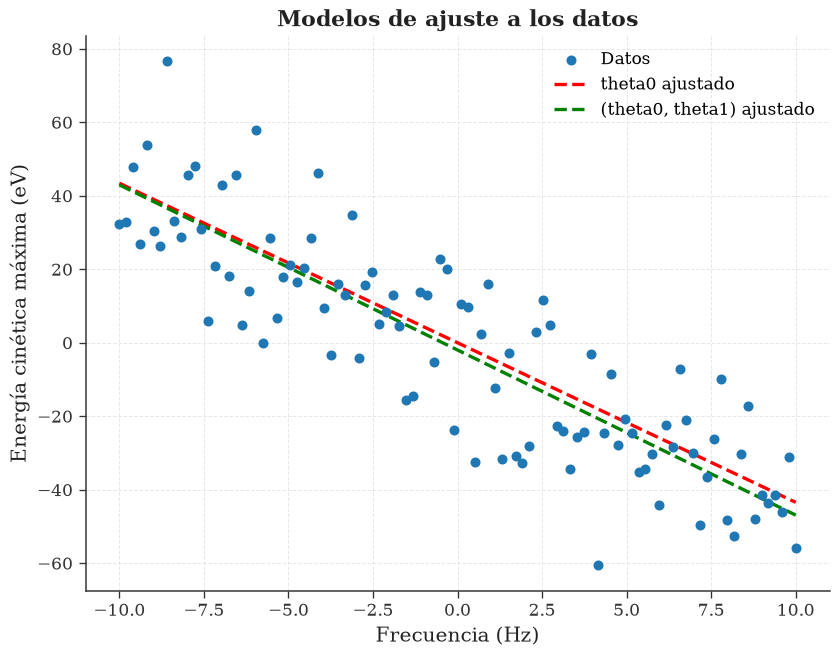

In [6]:
print('Grafiquemos el Ajuste lineal con los valores de theta_0 y theta_1 que minimizan el coste cuadrático')

pred_model_2 = lambda X: linear_model([theta_0_grid[min_idx], theta_1_grid[min_idx]], X)

plt.figure(figsize=(8, 6))
plt.scatter(X, Y, label='Datos', zorder = 4)
plt.plot(X, pred_model(X), color='red',
         linestyle='--', label='theta0 ajustado', zorder = 2)
plt.plot(X, pred_model_2(X), color='green',
         linestyle='--', label = '(theta0, theta1) ajustado', zorder = 2)

plt.title('Modelos de ajuste a los datos')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Energía cinética máxima (eV)')
plt.grid(True, zorder = 0)
plt.legend()
plt.show()

-----

**5.)** Interprete geométricamente la forma de la función de coste e identifique el mínimo global.

**R:/** La función de coste $J(\theta_0,\theta_1)$ tiene la forma de un paraboloide. Esto implica que existe un único mínimo global. En el diagrama de curvas de nivel, esta superficie se representa mediante trayectos elipticos concéntricos y a medida que nos acercamos al centro, el coste disminuye hasta alcanzar su valor mínimo.

Para los datos analizados, el mínimo se encuentra aproximadamente en:

$$
\theta_0=-3.1818,\qquad \theta_1=-4.2929
$$

**6.** Repita el procedimiento para un conjunto de datos con ruido y compare los resultados con el caso ideal.

--- COMPARACIÓN DE AJUSTES ---
CASO IDEAL (Sin ruido):
Theta_0: -0.1515 | Theta_1: -4.4949

CASO REAL (Con ruido dev=15.0):
Theta_0: -1.9697 | Theta_1: -4.4949


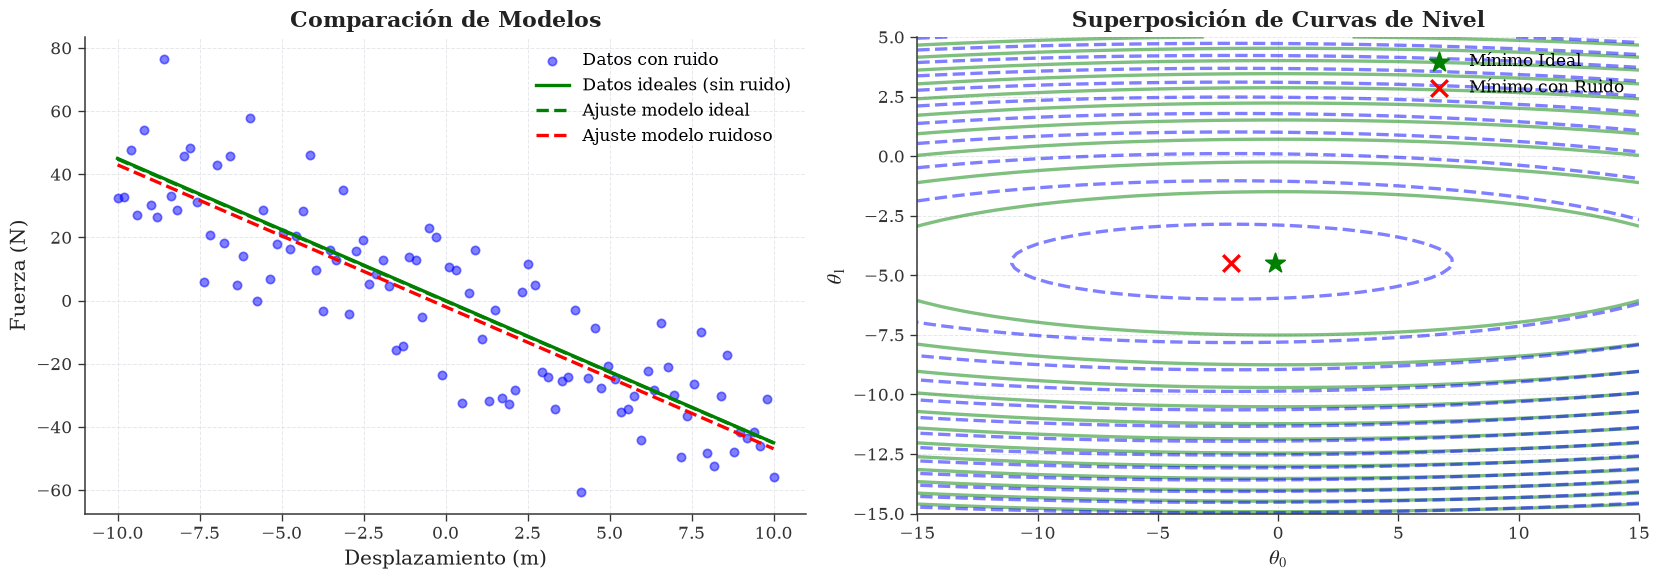

In [7]:
# 6. Comparación: Caso Ideal vs Caso con Ruido
#Generamos los datos ideales (sin ruido)

Y_ideal = -k * X

#Calculemos la función de coste para el caso ideal usando la misma malla
J_grid_ideal = coste_func_grid(theta_0_grid, theta_1_grid, X, Y_ideal)
# Encontramos el mínimo del caso ideal
min_idx_ideal = np.unravel_index(np.argmin(J_grid_ideal), J_grid_ideal.shape)
min_t0_ideal = theta_0_grid[min_idx_ideal]
min_t1_ideal = theta_1_grid[min_idx_ideal]
min_coste_ideal = J_grid_ideal[min_idx_ideal]

# Recuperamos el mínimo del caso con ruido
min_t0_ruido = theta_0_grid[min_idx]
min_t1_ruido = theta_1_grid[min_idx]
min_coste_ruido = J_grid_result[min_idx]


print("--- COMPARACIÓN DE AJUSTES ---")
print(f"CASO IDEAL (Sin ruido):")
print(f"Theta_0: {min_t0_ideal:.4f} | Theta_1: {min_t1_ideal:.4f}")
print(f"\nCASO REAL (Con ruido dev=15.0):")
print(f"Theta_0: {min_t0_ruido:.4f} | Theta_1: {min_t1_ruido:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica de datos
axes[0].scatter(X, Y, label='Datos con ruido', color='blue', alpha=0.5, zorder=1)
axes[0].plot(X, Y_ideal, label='Datos ideales (sin ruido)', color='green', linewidth=2, zorder=2)
axes[0].plot(X, min_t0_ideal + min_t1_ideal * X, label='Ajuste modelo ideal', color='green', linestyle='--', zorder=3)
axes[0].plot(X, min_t0_ruido + min_t1_ruido * X, label='Ajuste modelo ruidoso', color='red', linestyle='--', zorder=3)
axes[0].set_title('Comparación de Modelos')
axes[0].set_xlabel('Desplazamiento (m)')
axes[0].set_ylabel('Fuerza (N)')
axes[0].legend()
axes[0].grid(True)

# Gráfica de contornos
levels = np.linspace(0, np.max(J_grid_result), 15)

# Contorno ideal
axes[1].contour(theta_0_grid, theta_1_grid, J_grid_ideal, levels=levels, colors='green', alpha=0.5, linestyles='solid')
axes[1].scatter(min_t0_ideal, min_t1_ideal, color='green', marker='*', s=150, label='Mínimo Ideal')

# Contorno con ruido
axes[1].contour(theta_0_grid, theta_1_grid, J_grid_result, levels=levels, colors='blue', alpha=0.5, linestyles='dashed')
axes[1].scatter(min_t0_ruido, min_t1_ruido, color='red', marker='x', s=100, label='Mínimo con Ruido')

axes[1].set_title('Superposición de Curvas de Nivel')
axes[1].set_xlabel(r'$\theta_0$')
axes[1].set_ylabel(r'$\theta_1$')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

**R:/** Nótese que los datos tratados anteriormente incluyen una componente de ruido dada por `dev = 15`, ahora por tanto se realizará el tratamiento con los datos ideales.

 Los parámetros obtenidos ($\theta_0 = -3.18 , \theta_1 = -4.29$)  sufren una leve desviación respecto a los valores reales. Esto ocurre porque el modelo ajusta la recta intentando equilibrar los puntos dispersos aleatoriamente, "absorbiendo" parte del ruido en los parámetros de la recta. Los parámetros correspondientes a los datos ideales son $\theta_0 = -0.15 \approx 0.0, \theta_1 = -4.49 \approx -4.5$ siendo este último compatible con el valor impuesto inicialmente sobre la constante elastica $k$ y el modelo lineal que siguen los datos ideales.

----

**7.** Analice el efecto de introducir un valor atípico en el conjunto de datos. Discuta cómo cambia la solución y qué limitaciones presenta la función de coste cuadrática.

--- RESULTADOS INGRESANDO OUTLIER ---
Parámetros sin outlier: Theta_0 = -1.9697 | Theta_1 = -4.4949
Parámetros con outlier: Theta_0 = -1.0606 | Theta_1 = -4.0909


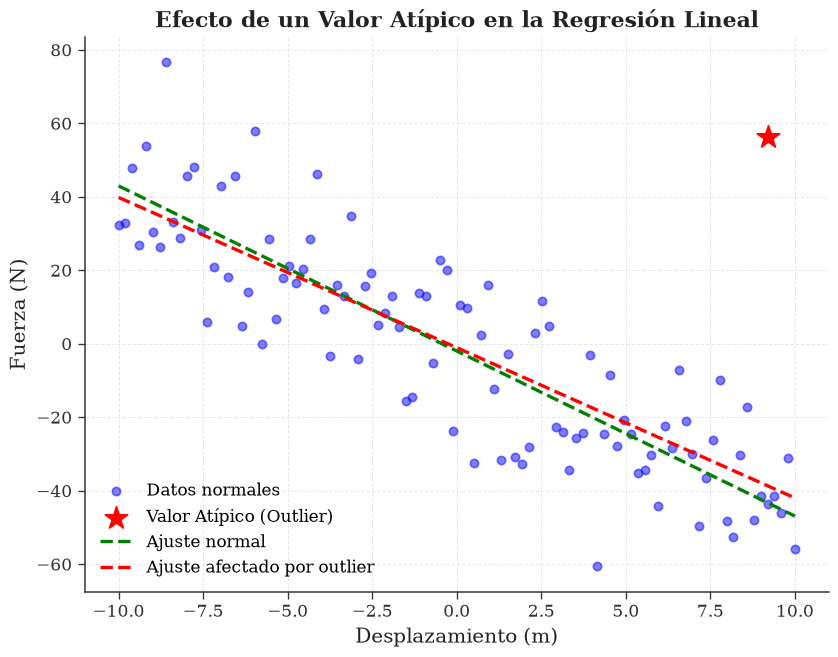

In [8]:
#7. Agreguegemos un outliers a los datos

Y_out = Y.copy()
Y_out[-5] += 100  # Agregamos un outlier en alguno de los datos

#Recalculamos la función de coste para el caso con outlier usando la misma malla
J_grid_outlier = coste_func_grid(theta_0_grid, theta_1_grid, X, Y_out)

# Encontramos el nuevo mínimo
min_idx_out = np.unravel_index(np.argmin(J_grid_outlier), J_grid_outlier.shape)
min_t0_out = theta_0_grid[min_idx_out]
min_t1_out = theta_1_grid[min_idx_out]

print("--- RESULTADOS INGRESANDO OUTLIER ---")
print(f"Parámetros sin outlier: Theta_0 = {min_t0_ruido:.4f} | Theta_1 = {min_t1_ruido:.4f}")
print(f"Parámetros con outlier: Theta_0 = {min_t0_out:.4f} | Theta_1 = {min_t1_out:.4f}")


plt.figure()
# Datos originales y outlier
plt.scatter(X, Y, color='blue', alpha=0.5, label='Datos normales')
plt.scatter(X[-5], Y_out[-5], color='red', marker='*', s=200, label='Valor Atípico (Outlier)', zorder=5)

plt.plot(X, min_t0_ruido + min_t1_ruido * X, label='Ajuste normal', color='green', linestyle='--')
plt.plot(X, min_t0_out + min_t1_out * X, label='Ajuste afectado por outlier', color='red', linestyle='--')

plt.title('Efecto de un Valor Atípico en la Regresión Lineal')
plt.xlabel('Desplazamiento (m)')
plt.ylabel('Fuerza (N)')
plt.legend()
plt.grid(True)
plt.show()


**R:/** Un valor atípico puede atraer la recta de regresión hacia el, modificando significativamente la pendiente $\theta_1$ y el intercepto $\theta_0$ para outliers muy alejados. Esto puede perjudicar el ajuste de la mayoría de los datos y reducir la capacidad de generalización del modelo. Lo anterior debido a que los errores se elevan al cuadrado en la función de coste $J(\theta_0 , \theta_1)$. Por ello, un valor atípico puede dominar la función de coste y llevar al algoritmo a modificar la recta para reducir su error. En consecuencia, el error cuadrático es sensible a los valores atípicos y por tanto la función de coste es sensible a estos.

-------

**8.** Compare el ajuste obtenido con un modelo lineal sobre un conjunto de datos no lineales. Discuta si minimizar la función de coste garantiza que el modelo sea adecuado.

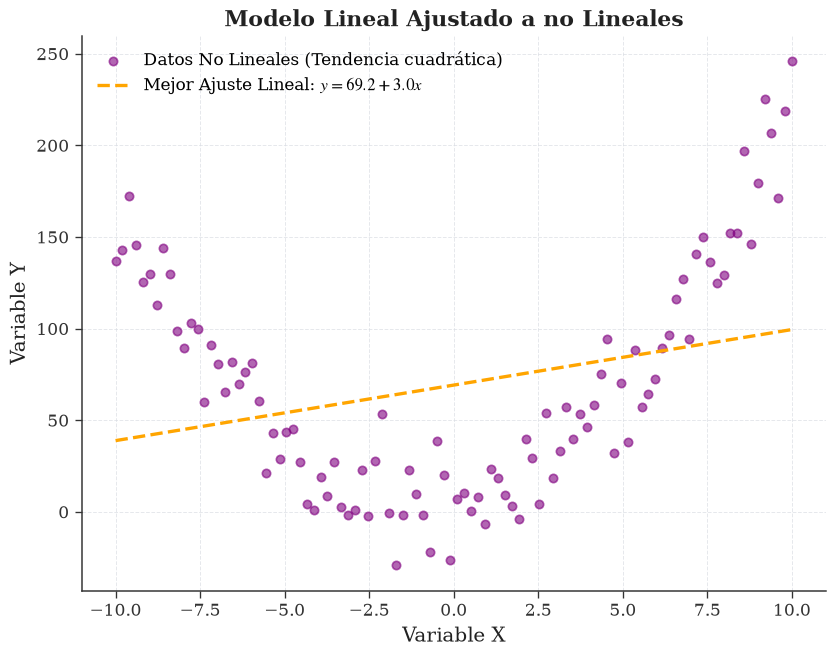

El coste mínimo encontrado para este ajuste es: 1795.87
Los parámetros que minimizan el coste son: Theta_0 = 69.1919, Theta_1 = 3.0303


In [9]:
# 8. Ajuste de un modelo lineal a datos NO lineales

#Datos no lineales de modelo cuadrático con ruido
X_nl = np.linspace(-10, 10, 100)
# Ecuación no lineal: y = 2x^2 + 3x + ruido
Y_nl = 2 * (X_nl**2) + 3 * X_nl + np.random.normal(0, 20, 100)

# 2. Buscamos el mejor ajuste lineal usando una malla adaptada a estos datos
t0_range = np.linspace(-50, 150, 100)
t1_range = np.linspace(-20, 20, 100)
T0_nl, T1_nl = np.meshgrid(t0_range, t1_range)

#Recalculamos la función de coste para los datos no lineales usando la misma malla
J_grid_nl = coste_func_grid(T0_nl, T1_nl, X_nl, Y_nl)

# Encontramos el mínimo para los datos no lineales
min_idx_nl = np.unravel_index(np.argmin(J_grid_nl), J_grid_nl.shape)
min_t0_nl = T0_nl[min_idx_nl]
min_t1_nl = T1_nl[min_idx_nl]

# --- GRAFICACIÓN ---
plt.figure(figsize=(8, 6))

# Datos no lineales
plt.scatter(X_nl, Y_nl, color='purple', alpha=0.6, label='Datos No Lineales (Tendencia cuadrática)')

# Mejor ajuste lineal
plt.plot(X_nl, min_t0_nl + min_t1_nl * X_nl, color='orange', linestyle = '--',
         label=f'Mejor Ajuste Lineal: $y = {min_t0_nl:.1f} + {min_t1_nl:.1f}x$')

plt.title('Modelo Lineal Ajustado a no Lineales')
plt.xlabel('Variable X')
plt.ylabel('Variable Y')
plt.legend()
plt.grid(True)
plt.show()

print(f"El coste mínimo encontrado para este ajuste es: {J_grid_nl[min_idx_nl]:.2f}")
print(f"Los parámetros que minimizan el coste son: Theta_0 = {min_t0_nl:.4f}, Theta_1 = {min_t1_nl:.4f}")

Visualmente, el modelo lineal fracasa por completo en capturar la verdadera estructura de los datos. La recta solo logra atravesar la nube de puntos por el medio para equilibrar los errores positivos y negativos, pero sus predicciones presentan errores sistemáticos enormes.

La minimización de la función de coste $J(\theta_0 , \theta_1)$ se hace perfectamente pero no representa el comportamiento de los datos que siguen de entrada un modelo cuadrático, por tanto se calcula la mejor recta que se ajusta a los datos haciendo una minimización global, pero es un modelo inútil dado que la optimización de la función de coste es ciega al contexto real de los datos.

La hipótesis $h(X)$ propuesta inicialmente no es correcta para estos datos por tanto una optimización será invalida como paso a seguir, bajo un supuesto falso.

----

**9.** Obtenga la expresión teórica de la función de coste en el caso con un parámetro y con dos parámetros, e interprete el significado de sus mínimos.

**R:/** J es una función mide la distancia euclidiana al cuadrado entre las predicciones de un modelo $h(x)$ y los respectivos valores reales $y$, sin embargo esta no es la única función de coste existente, pero si es la aplicable para el caso de modelos de regresión lineal, que es núcleo de este trabajo

* **Expresión analítica para $J(\theta_0)$:**

Suponemos que un modelo $h_{\theta}(x)$ posee un único parámetro $\theta_0$, donde esta se expresa como $h_{\theta}(x) = \theta_0 x$, lo que equivale a un modelo lineal pasando por el origen. La función de coste de error cuadrático medio se expresa como:

$$
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_{\theta}(X^{(i)})-y^{(i)}\right)^2
$$

Luego con $h_{\theta}(x) = \theta_0 x$, se llega a la expresión:

$$
J(\theta_0) =  \frac{1}{2m}\sum_{i=1}^{m}\left(\theta_0 x^{(i)}-y^{(i)}\right)^2
$$

Expandiendo el cuadrado se llega a que

$$
J(\theta_0) =  \left(\frac{1}{2m}\sum (x^{(i)})^2\right)\theta_0^2
-\left(\frac{1}{m}\sum x^{(i)}y^{(i)}\right)\theta_0
+\left(\frac{1}{2m}\sum (y^{(i)})^2\right)
$$

Nótese entonces que este modelo es de la forma $f(x) = ax^2 + bx + c$ por lo tanto $J(\theta_0)$ es una parábola concava hacia arriba, con lo cuál solo existe un mínimo global que es el punto vértice de dicha parábola, por lo cuál $\frac{dJ}{d\theta_0}=0$ representa el punto mínimo de la función de coste. Finalmente es claro que encontrando el punto que minimiza $J(\theta_0)$ se busca el valor de la pendiente $\theta_0$ que corresponde a la recta que mejor se ajusta a la distribución de datos.

* **Expresión analítica para $J(\theta_0, \theta_1)$:**

Usamos la expresión general de un modelo lineal con parámetros $\theta_0, \theta_1$ 

$$
h_{\theta}(x) = \theta_0 x + \theta_1
$$

Por tanto la función de coste $J(\theta_0, \theta_1)$ sigue la expresión

$$
J(\theta_0, \theta_1) =  \frac{1}{2m}\sum_{i=1}^{m}\left(\theta_1 + \theta_0 x^{(i)}-y^{(i)}\right)^2
$$

Posteriormente expandiendo el cuadrado de la anterior expresión se llega a 

$$
J(\theta_0,\theta_1) = \frac{1}{2m}\sum_{i=1}^{m} \theta_1^2 + 2\theta_0\theta_1 x^{(i)} - 2\theta_1 y^{(i)}
+ \theta_0^2 (x^{(i)})^2 - 2\theta_0 x^{(i)}y^{(i)} + (y^{(i)})^2
$$

$J(\theta_0, \theta_1)$ Representa geometricamente un paraboloide elíptico, que analogamente al caso de un solo parámetro, esta función estrictamente convexa solo posee un mínimo global en el punto centroide del paraboloide, por lo que los valores $\theta_0,\theta_1$ que minimizan la función de coste estan dados correspondientemente por 

$$
\frac{dJ}{d\theta_0} = 0, \frac{dJ}{d\theta_1} = 0 \rightarrow \nabla{J(\theta_0, \theta_1)} = \begin{bmatrix}
\theta_0 = 0 \\
\theta_1 = 0
\end{bmatrix}
$$

Es claro además que el par $(\theta_0, \theta_1)$ representan correspondientemente los parámetros que definen la mejor recta que define los datos, siendo el intersecto y pendiente correspondientemente.


----

## Gradiente descendente

Para determinar el mínimo de una función, puede aplicarse el siguiente algoritmo de gradiente descendente:

- Proponer un número aleatorio inicial $\omega_i$.
- Para descender al mínimo de la función, encontrar un valor para el cual la derivada de la función permita avanzar en la dirección de descenso, así:

\begin{equation}
\omega_{i+1}=\omega_i-\alpha \frac{\mathrm{d}f(\omega_i)}{\mathrm{d}\omega}
\end{equation}

donde $\alpha$ es conocido como la tasa de aprendizaje del algoritmo.

- Evaluar $f(\omega_{i+1})$.
- Iterar hasta encontrar el mínimo de la función.

----

**10.** Construya un algoritmo en el que emplee el gradiente descendente para determinar el mínimo de una función. Determine dicho mínimo con un error $\epsilon$ de $10^{-4}$. Pruebe su algoritmo para

$$
f(x)=(x-4)^2
$$

y al menos tres valores diferentes de $\alpha$.

In [10]:
#PASO 1: Construimos el algoritmo de Gradiente Descendente

def grad_desc(alpha, epsilon=1e-4, max_iter=1000, x_init=0.0):
    """
    Algoritmo de gradiente descendente para 1 variable.
    alpha: tasa de aprendizaje
    epsilon: criterio de parada (error tolerado entre pasos)
    x_init: valor inicial aleatorio (empezaremos en 0.0)
    """
    x_vals = [x_init] # Guardamos la historia para graficar
    x_current = x_init
    
    for i in range(max_iter):
        # Calculamos el gradiente (derivada) en el punto actual
        grad = df(x_current)
        
        # Actualizamos el valor (regla del gradiente descendente)
        x_next = x_current - alpha * grad
        
        x_vals.append(x_next)
        
        # Criterio de parada: Si el cambio entre el paso anterior y el nuevo es menor al error
        if abs(x_next - x_current) < epsilon:
            break
            
        x_current = x_next

    # Retorna el historial y el número de iteraciones
    return np.array(x_vals), i+1 

In [11]:
#PASO 2: Definimos la función y su derivada analítica
def f(x):
    return (x - 4)**2

def df(x):
    return 2 * (x - 4)

#para (x-4)^2, el mínimo se encuentra en x=4

# PASO 3: Probemos con 3 valores de alpha diferentes
alphas = [0.05, 0.3, 0.8]
epsilon = 1e-4

print("--- RESULTADOS DEL GRADIENTE DESCENDENTE ---")
print(f"Buscando el mínimo de f(x) = (x-4)^2 con epsilon = {epsilon}\n")

for idx, alpha in enumerate(alphas):
    # Ejecutamos el algoritmo
    hist_x, its = grad_desc(alpha, epsilon)
    hist_y = f(hist_x)
    
    # Imprimimos resultados
    x_min_encontrado = hist_x[-1]
    print(f"Alpha = {alpha}:")
    print(f"  - Mínimo encontrado en x = {x_min_encontrado:.5f}")
    print(f"  - Iteraciones necesarias = {its}")

--- RESULTADOS DEL GRADIENTE DESCENDENTE ---
Buscando el mínimo de f(x) = (x-4)^2 con epsilon = 0.0001

Alpha = 0.05:
  - Mínimo encontrado en x = 3.99913
  - Iteraciones necesarias = 80
Alpha = 0.3:
  - Mínimo encontrado en x = 3.99997
  - Iteraciones necesarias = 13
Alpha = 0.8:
  - Mínimo encontrado en x = 4.00003
  - Iteraciones necesarias = 23


----

**11.** Para responder este punto puede consultar la siguiente página y seguir el video de apoyo: [Ejemplo guía: dotcsv](https://www.youtube.com/watch?v=-_A_AAxqzCg)

Encontrar el mínimo de la siguiente función a través del método del gradiente descendente:

\begin{equation}
F(x,y)=\sin\left(\frac{1}{2}x^2-\frac{1}{4}y^2+3\right)\cos(2x+1-e^y)
\end{equation}

- Para ello, realice una gráfica de la función en 3D y un mapa de contorno de la función.
- Determine el valor mínimo de la función con el método del gradiente descendente.

In [12]:
F = lambda vars: np.sin(0.5 * vars[0]**2 - 0.25 * vars[1]**2 + 3) * np.cos(2 * vars[0] + 1 - np.exp(vars[1]))

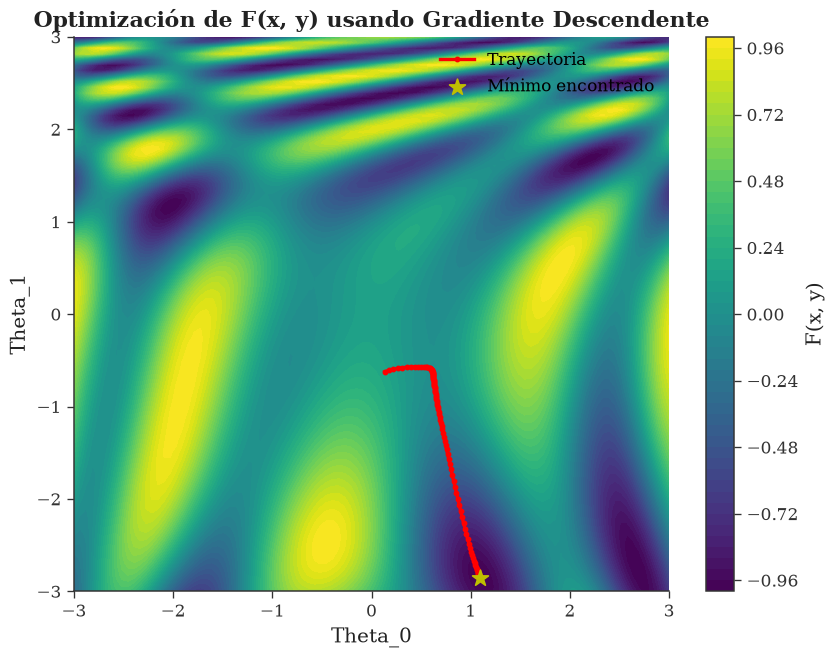

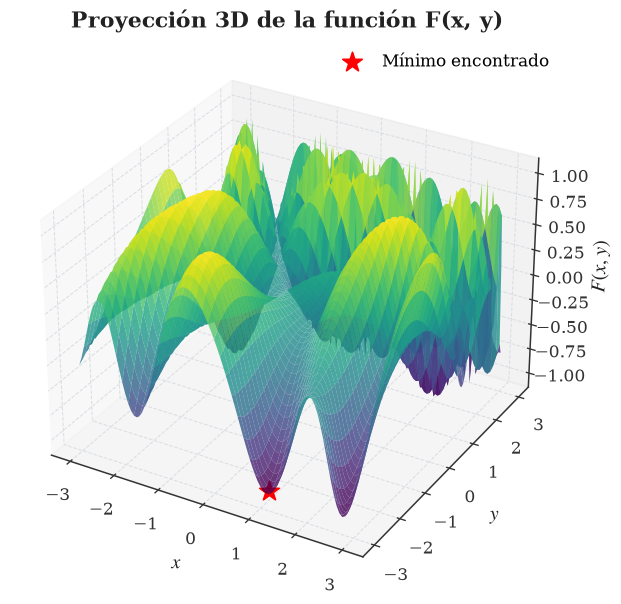

In [13]:
#Definamos grad_desc_2d para una función F(x, y) generalizada
#Basados en el video de Dot CSV https://www.youtube.com/watch?v=-_A_AAxqzCg

def grad_desc_2d(F, Theta, alpha=0.1, h=0.01, max_iter=1000, x_init=None, args=()):
    """
    Algoritmo de gradiente descendente para funciones de 2 variables.
    F: función a minimizar, debe aceptar un array de 2 elementos (x, y)
    Theta: array inicial de parámetros [theta_0, theta_1]
    alpha: tasa de aprendizaje
    h: paso para la aproximación de la derivada
    max_iter: número máximo de iteraciones
    x_init: valor inicial opcional para Theta
    """

    Theta = np.array(Theta, dtype=float)
    grad = np.zeros_like(Theta)
    trayectoria = [Theta.copy()]

    if x_init is not None:
        Theta = np.array(x_init, dtype=float)

    # Iteramos hasta alcanzar el número máximo de iteraciones
    for it in range(max_iter):
        for j in range(len(Theta)):
            _T = Theta.copy()
            _T[j] += h

            # Aproximación de la derivada parcial
            grad[j] = (F(_T,*args) - F(Theta, *args)) / h

        # Actualización de los parámetros
        Theta = Theta - alpha * grad
        trayectoria.append(Theta.copy())

    return Theta, np.array(trayectoria)

#Apliquemos grad_desc_2d a la función F(x, y) definida anteriormente

Theta = np.random.rand(2) * 4 - 2  # Inicializamos aleatoriamente entre -2 y 2

#grad_desc_2d para la función F(x, y)
Theta_min, trayectoria = grad_desc_2d(F, Theta, alpha=0.1, h=0.01, max_iter=1000)

#Malla para graficar la función F(x, y)
X, Y = np.meshgrid(np.linspace(-3, 3, 100), np.linspace(-3, 3, 100))
Z = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        Z[i, j] = F([X[i, j], Y[i, j]])

#Mapa de Contorno de la función F(x, y)
plt.figure(figsize=(8, 6))
plt.contourf(X, Y, Z, levels=50, cmap='viridis')
plt.colorbar(label='F(x, y)')
plt.plot(trayectoria[:, 0], trayectoria[:, 1], 'r.-', label='Trayectoria')

plt.scatter(Theta_min[0], Theta_min[1], marker='*', s=100, c='y',
            label='Mínimo encontrado', zorder=5)
plt.title('Optimización de F(x, y) usando Gradiente Descendente')
plt.xlabel('Theta_0')
plt.ylabel('Theta_1')
plt.legend()
plt.show()

#Grafiquemos la superficie 3Dimensional
# Gráfica 3D de la función
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Superficie de la función
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.8, zorder=1)

# Mínimo encontrado
ax.scatter(
    Theta_min[0], Theta_min[1], F(Theta_min),
    marker='*', color='red', s=150, label='Mínimo encontrado', zorder=5
)

# Configuración
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_zlabel('$F(x,y)$')
ax.set_title('Proyección 3D de la función F(x, y)')
ax.legend()

plt.show()

-----

## Modelo de *machine learning*: solución general

Un modelo general para solucionar un problema de *machine learning* puede ser estructurado como sigue:

### a. Elegir el modelo a emplear

\begin{equation}
h(X,\Theta)
\end{equation}

- En el caso de una regresión lineal, tenemos que $h(X,\Theta=(\theta_0,\theta_1))$:

\begin{equation}
h(X)=\theta_0+\theta_1X
\end{equation}

### b. Elegir la función de coste

- Métrica euclidiana:

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_{\theta}(X^{(i)})-y^{(i)}\right)^2
\end{equation}

- [Lista de funciones de coste que pueden ser empleadas](https://jmlb.github.io/flashcards/2018/04/21/list_cost_functions_fo_neuralnets/)

### c. Aplicar el gradiente descendente iterativamente hasta encontrar el mínimo

\begin{equation}
\Delta \vec{\Theta}=-\alpha \nabla J(\Theta)
\end{equation}

- En el caso de una regresión lineal, tenemos que $h(X,\Theta=(\theta_0,\theta_1))$:

\begin{equation}
\theta_0 := \theta_0-\alpha \frac{\partial J}{\partial \theta_0}
\end{equation}

\begin{equation}
\theta_1 := \theta_1-\alpha \frac{\partial J}{\partial \theta_1}
\end{equation}

----

**12.** Empleando los siguientes datos:

```python
X = np.linspace(0, 1, 100)
y = 0.2 + 0.2*X + 0.02*np.random.random(100)
```

y las herramientas desarrolladas en los apartados anteriores, construya un algorítmo que permita determinar una regresión lineal. 

In [14]:
#Datos Iniciales
np.random.seed(42)
X = np.linspace(0, 1, 100)
y = 0.2 + 0.2*X + 0.02*np.random.random(100)

#Definamos una función de coste como anteriormente
def coste_func_(Theta, X, y):
    """
    Calcula el coste cuadrático para una regresión lineal.
    Theta: array de parámetros [theta_0, theta_1]
    X: array de características
    y: array de valores reales
    """
    m = len(y)
    predict = Theta[0] + Theta[1] * X
    return 1/(2*m) * np.sum((predict - y)**2)

#Utilicemos grad_desc_2d para minimizar la función de coste

Theta_opt, trayectoria = grad_desc_2d(
    F=coste_func_,
    args=(X, y),
    Theta=[0, 0],
    alpha=0.5,
    h=0.01,
    max_iter=1000
)

t0_opt, t1_opt = Theta_opt


#Calculemos El error cuadratico medio final
final_cost = coste_func_(Theta_opt, X, y)

print('--- RESULTADOS DEL GRADIENTE DESCENDENTE PARA REGRESIÓN LINEAL ---')
print(f"Theta_0 óptimo (Intercepto): {t0_opt:.4f}")
print(f"Theta_1 óptimo (Pendiente): {t1_opt:.4f}")
print(f"Coste final o error cuadrático: {final_cost:.6f}")

--- RESULTADOS DEL GRADIENTE DESCENDENTE PARA REGRESIÓN LINEAL ---
Theta_0 óptimo (Intercepto): 0.1993
Theta_1 óptimo (Pendiente): 0.2101
Coste final o error cuadrático: 0.000034


**13.** Compare su resultado empleando la libreria linearRegresion() de sklearn.

--- RESULTADOS DE Scikit-learn ---
Intercepto (Theta_0): 0.2092
Pendiente (Theta_1): 0.2004
Error cuadrático medio: 0.000035
Tiempo de ejecución: 0.0150 segundos


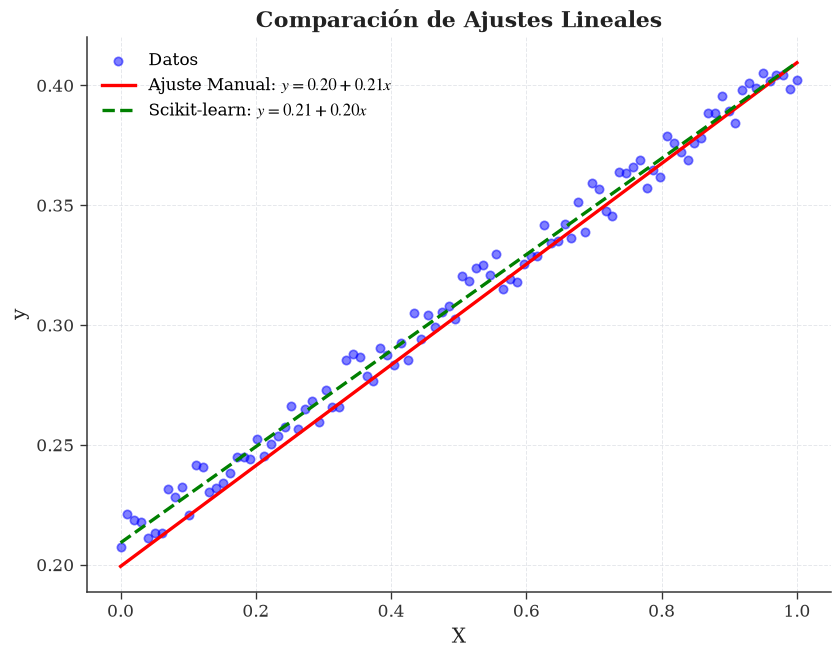

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from time import time

# Ajuste de un modelo lineal usando scikit-learn
X_sk = X.reshape(-1, 1)

time_init = time()
modelo_sk = LinearRegression()
modelo_sk.fit(X_sk, y)
time_taken = time() - time_init
y_pred = modelo_sk.predict(X_sk)
mse = mean_squared_error(y, y_pred)

print('--- RESULTADOS DE Scikit-learn ---')
print(f"Intercepto (Theta_0): {modelo_sk.intercept_:.4f}")
print(f"Pendiente (Theta_1): {modelo_sk.coef_[0]:.4f}")
print(f"Error cuadrático medio: {mse:.6f}")
print(f"Tiempo de ejecución: {time_taken:.4f} segundos")

#Graficamos la comparación entre el ajuste manual y el de scikit-learn
plt.figure(figsize=(8, 6))
# Datos originales
plt.scatter(X, y, label='Datos', color='blue', alpha=0.5)
# Línea de regresión ajustada manualmente 
plt.plot(X, t0_opt + t1_opt * X, color='red', label=f'Ajuste Manual: $y = {t0_opt:.2f} + {t1_opt:.2f}x$', linewidth=2)
# Línea de regresión ajustada con scikit-learn
plt.plot(X, modelo_sk.predict(X_sk), color='green', linestyle='--', label=f'Scikit-learn: $y = {modelo_sk.intercept_:.2f} + {modelo_sk.coef_[0]:.2f}x$', linewidth=2)
plt.title('Comparación de Ajustes Lineales')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

Al comparar el algoritmo de gradiente descendente numérico implementado desde cero con la biblioteca Scikit-Learn, se obtuvieron los siguientes resultados:

Scikit-Learn calculó un intercepto de $\theta_0 \approx 0.209$ y una pendiente de $\theta_1 \approx 0.200$. Este resultado es coherente con el ruido agregado a los datos originales ($0.02 \times \text{random}$), cuyo valor esperado es $0.01$, lo que desplaza el intercepto esperado de $0.20$ a $0.21$.

Por su parte, el algoritmo propio obtuvo un intercepto de $\theta_0 \approx 0.199$ y una pendiente de $\theta_1 \approx 0.210$.

Aunque existe una ligera variación entre los parámetros estimados por ambos modelos, del orden de las centésimas, el análisis de la función de coste evidencia el buen desempeño del algoritmo implementado. El error cuadrático final del modelo propio fue de $0.000034$, un valor prácticamente igual al obtenido con Scikit-Learn ($0.000035$).

-----




**14.** (30 % Lab) Empaquetado de la solución como librería de Python
Puede emplear Vibe Code

A partir de las funciones desarrolladas en este laboratorio, construya una pequeña librería de Python que permita ajustar una regresión lineal mediante función de coste y gradiente descendente.

La librería debe incluir:

1. Una función para calcular la hipótesis lineal.
2. Una función para calcular la función de coste.
3. Una función para ejecutar el gradiente descendente.
4. Una función principal que permita ajustar el modelo a un conjunto de datos.
5. Documentación básica de cada función.
6. Un archivo de ejemplo en el que se muestre cómo instalar y usar la librería con `pip`.

Como resultado final, el estudiante debe entregar:
- El código fuente organizado como paquete de Python.
- Un archivo `README.md` con instrucciones de instalación.
- La documentación de uso de la librería.
- Un ejemplo de ejecución sobre los datos del laboratorio.


### Hint

Pueden comprobar la solución de la superficie a partir de la forma matricial de la función de coste:

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left(h_{\Theta}(X^{(i)})-y^{(i)}\right)^2
\end{equation}

Sea

\begin{equation}
\Theta^T=[\theta_0,\theta_1]
\end{equation}

y sea la matriz de diseño

\begin{equation}
X=
\begin{bmatrix}
1 & 1 & 1 & \cdots & 1\\
x_1^{(1)} & x_1^{(2)} & x_1^{(3)} & \cdots & x_1^{(m)}
\end{bmatrix}
\end{equation}

de dimensión $(n+1)\times m$. En este caso, como solo se tiene una característica, $n=1$.

Luego, las predicciones del modelo pueden escribirse como

\begin{equation}
\Lambda=\Theta^T X=
\begin{bmatrix}
\theta_0+\theta_1 x_1^{(1)} &
\theta_0+\theta_1 x_1^{(2)} &
\theta_0+\theta_1 x_1^{(3)} &
\cdots &
\theta_0+\theta_1 x_1^{(m)}
\end{bmatrix}
\end{equation}

De esta manera, la función de coste se obtiene comparando estas predicciones con los valores reales $Y$:

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left(\Lambda_i-y^{(i)}\right)^2
\end{equation}

o, de forma equivalente, si definimos

\begin{equation}
Y=
\begin{bmatrix}
y^{(1)} & y^{(2)} & y^{(3)} & \cdots & y^{(m)}
\end{bmatrix},
\end{equation}

entonces

\begin{equation}
J(\Theta)=\frac{1}{2m}\sum_{i=1}^{m}\left((\Theta^T X)_i-Y_i\right)^2
\end{equation}

Por tanto, en Python, la verificación numérica puede realizarse calculando primero las predicciones, luego el error y finalmente el promedio del error cuadrático.

In [16]:
#Definimos aqui las funciones que contendrá nuestra libreria linear_reg.py

#------------------------------------------------------------------------------
#funcion de hipotesis para regresion lineal
def hipotesis(Theta, X):
    """
    Calcula la hipótesis para una regresión lineal. (vectorizada)
    theta: array de parámetros [theta_0, theta_1]
    X: array de características
    """
    return np.dot(X, Theta)  # Producto punto punto entre X y theta

#------------------------------------------------------------------------------
#Funcion de coste para regresion lineal (similar a la que usamos anteriormente)
def coste_func_(Theta, X, y):
    """
    Calcula el coste cuadrático para una regresión lineal.
    Theta: array de parámetros [theta_0, theta_1]
    X: array de características
    y: array de valores reales
    """
    m = len(y)
    predict = hipotesis(Theta, X)
    return 1/(2*m) * np.sum((predict - y)**2)

#-----------------------------------------------------------------------------
#Funcion de gradiente descendente para regresion lineal
#Deb ser compatible con la funcion de coste definida anteriormente y la hipotesis
def grad_desc_2d(X, y, Theta, alpha=0.1, h=0.01, max_iter=1000):
    """
    Gradiente descendente numérico para regresión lineal.
    X: matriz de características, incluyendo la columna de unos.
    y: valores reales.
    Theta: parámetros iniciales [theta_0, theta_1].
    alpha: tasa de aprendizaje.
    h: paso para la aproximación numérica del gradiente.
    max_iter: número máximo de iteraciones.
    """

    Theta = np.array(Theta, dtype=float)
    grad = np.zeros_like(Theta)
    trayectoria = [Theta.copy()]

    for _ in range(max_iter):
        for j in range(len(Theta)):
            _T = Theta.copy()
            _T[j] += h

            # Aproximación de la derivada parcial
            grad[j] = (
                coste_func_(_T, X, y) - coste_func_(Theta, X, y)
            ) / h

        # Actualización de los parámetros
        Theta = Theta - alpha * grad
        trayectoria.append(Theta.copy())

    return Theta, np.array(trayectoria)

#-----------------------------------------------------------------------------
#Funcion de ajuste de modelo lineal a un conjunto de datos
def ajustar_modelo(X_train, y_train, alpha=0.1, max_iter=1000):
    """
    Función principal para ajustar la regresión lineal a un conjunto de datos.
    Prepara la matriz de diseño y llama al gradiente descendente.
    
    Args:
        X_train (np.ndarray): Vector de características X (dimensión m).
        y_train (np.ndarray): Vector de etiquetas reales y (dimensión m).
        alpha (float): Tasa de aprendizaje. Default: 0.1
        max_iter (int): Iteraciones máximas. Default: 1000
        
    Returns:
        tuple: (theta_optimo, historial_de_coste)
    """
    m = len(y_train)
    
    # Construcción de la Matriz de Diseño (agregando la columna de 1s para Theta_0)
    # X_b tendrá dimensiones (m, 2)
    X_b = np.c_[np.ones((m, 1)), X_train]
    
    # Inicializar Theta en [0, 0]
    theta_inicial = np.zeros(2)
    
    # Llamar al algoritmo
    theta_optimo, historial = grad_desc_2d(X_b, y_train, theta_inicial, alpha, max_iter)
    
    return theta_optimo, historial

**Ejemplo de uso de nuestra libreria `linear_reg`**

In [21]:
from lab_4_lin_reg_lib.lib import linear_reg

print("Funciones importadas correctamente desde linear_reg.py")
print(f"--"*50)
print(f"hipotesis: {linear_reg.hipotesis.__doc__}")
print(f"--"*50)
print(f"coste_func_: {linear_reg.coste_func_.__doc__}")
print(f"--"*50)
print(f"grad_desc_2d: {linear_reg.grad_desc_2d.__doc__}")
print(f"--"*50)
print(f"ajustar_modelo: {linear_reg.ajustar_modelo.__doc__}")

Funciones importadas correctamente desde linear_reg.py
----------------------------------------------------------------------------------------------------
hipotesis: 
    Calcula la hipótesis para una regresión lineal. (vectorizada)
    theta: array de parámetros [theta_0, theta_1]
    X: array de características
    
----------------------------------------------------------------------------------------------------
coste_func_: 
    Calcula el coste cuadrático para una regresión lineal.
    Theta: array de parámetros [theta_0, theta_1]
    X: array de características
    y: array de valores reales
    
----------------------------------------------------------------------------------------------------
grad_desc_2d: 
    Gradiente descendente numérico para regresión lineal.
    X: matriz de características, incluyendo la columna de unos.
    y: valores reales.
    Theta: parámetros iniciales [theta_0, theta_1].
    alpha: tasa de aprendizaje.
    h: paso para la aproximación numérica

Generando datos de prueba...
Ajustando el modelo mediante gradiente descendente numérico...

--- Resultados obtenidos ---
Theta_0 óptimo (Intercepto): 0.19935
Theta_1 óptimo (Pendiente):  0.21011
Coste Final (Error Cuadrático): 0.000034



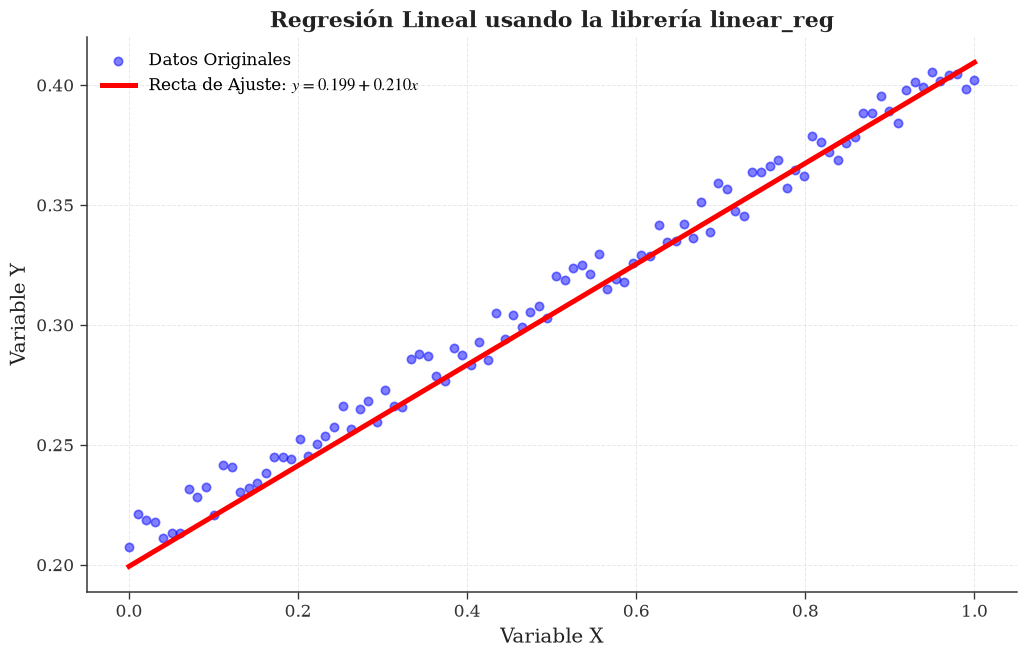

In [22]:
# --- Preparación de los datos ---
print("Generando datos de prueba...")
np.random.seed(42)
X_train = np.linspace(0, 1, 100)
y_train = 0.2 + 0.2 * X_train + 0.02 * np.random.random(100)

# --- Entrenamiento del modelo ---
print("Ajustando el modelo mediante gradiente descendente numérico...")
# Usamos alpha=0.5 ya que los datos de X están normalizados (entre 0 y 1)
theta_opt, trayectoria_theta = linear_reg.ajustar_modelo(
    X_train, y_train, alpha=0.5, max_iter=1500)

print("\n--- Resultados obtenidos ---")
print(f"Theta_0 óptimo (Intercepto): {theta_opt[0]:.5f}")
print(f"Theta_1 óptimo (Pendiente):  {theta_opt[1]:.5f}")

# --- Cálculo del error final ---
# Necesitamos la matriz de diseño (con la columna de unos)
X_b = np.c_[np.ones((len(X_train), 1)), X_train]

coste_final = linear_reg.coste_func_(theta_opt, X_b, y_train)
print(f"Coste Final (Error Cuadrático): {coste_final:.6f}\n")

# --- Graficacion ---
plt.figure(figsize=(10, 6))

# Dibujamos los datos de entrenamiento
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Datos Originales')

# Predicciones del modelo ajustado
y_pred = linear_reg.hipotesis(theta_opt, X_b)

# Dibujamos la recta de regresión encontrada
plt.plot(X_train, y_pred, color='red', linewidth=3, 
         label=f'Recta de Ajuste: $y = {theta_opt[0]:.3f} + {theta_opt[1]:.3f}x$')

plt.title('Regresión Lineal usando la librería linear_reg')
plt.xlabel('Variable X')
plt.ylabel('Variable Y')
plt.legend()
plt.grid(True)
plt.show()